In [4]:
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
%matplotlib inline
df = pd.read_csv("cars_cleaned.csv")
print(df.shape)
df.head()

(12494, 21)


,list_id,subject,price_million,mfdate,car_age,odo_km,carbrand_name,carmodel_name,region_name,region_name_v3,...,ward_name,list_time,flag_chinh_chu,flag_bao_duong_hang,gearbox,fuel,cartype,carcolor,carorigin,carseats
0,94613937,ISUZU DMAX NHẬP THÁI SỐ TỰ ĐỘNG SIÊU KENG RẤT ĐẸP,475.0,2014,12,80000.0,Isuzu,Dmax,An Giang,An Giang,...,Thị trấn Mỹ Luông,1786860877000,0,0,Số tự động,Dầu,Bán tải,Unknown,Nhập khẩu Thái Lan,Unknown
1,101546338,Ranger XLS AT,615.0,2025,1,22000.0,Ford,Ranger,Hà Nội,TP Hà Nội,...,Phường Hoàng Liệt,1787635662939,0,0,Số tự động,Dầu,Bán tải,Trắng,Lắp ráp trong nước,5 chỗ
2,101725648,terano ll máy dầu 7 chỗ diezen 2 cầu tubo xe đẹp,140.0,2002,24,130000.0,Nissan,Terrano,Hà Nội,TP Hà Nội,...,Phường Phúc La,1785372154000,0,0,Số sàn,Dầu,SUV / Crossover,Unknown,Nhập khẩu Nhật Bản,7 chỗ
3,103030971,BMW X6 2010 Full Đồ Chơi Của Hãng,638.0,2010,16,105000.0,BMW,X6,Hồ Chí Minh,TP Hồ Chí Minh,...,Phường Tam Bình (Quận Thủ Đức cũ),1788411834744,0,0,Số tự động,Xăng,SUV / Crossover,Đen,Unknown,Mã 4
4,109039668,Toyota Fortuner 4x2 2016 một chủ,439.0,2016,10,120000.0,Toyota,Fortuner,Hà Nội,TP Hà Nội,...,Phường Hoàng Liệt,1787024581986,1,0,Số sàn,Xăng,SUV / Crossover,Bạc,Lắp ráp trong nước,7 chỗ


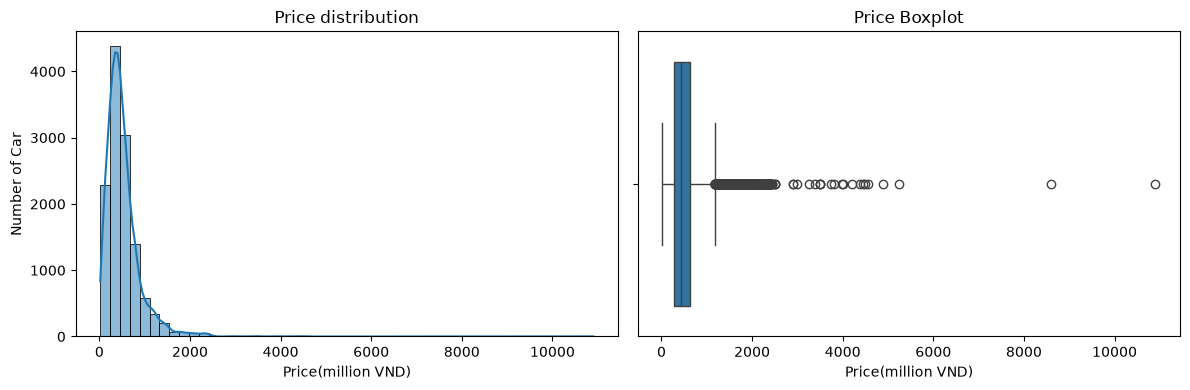

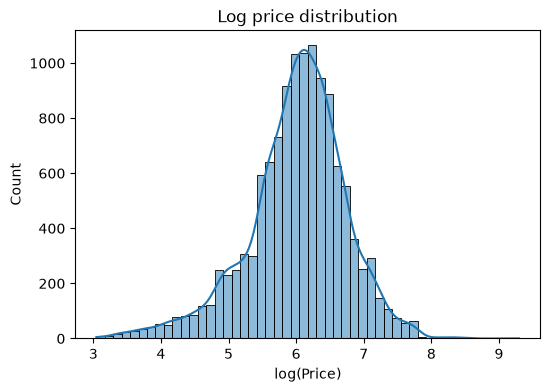

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["price_million"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Price distribution")
ax[0].set_xlabel("Price(million VND)")
ax[0].set_ylabel("Number of Car")

sns.boxplot(x=df["price_million"], ax=ax[1])
ax[1].set_title("Price Boxplot")
ax[1].set_xlabel("Price(million VND)")


plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 4))
sns.histplot(np.log1p(df["price_million"]), bins=50, kde=True)
plt.title("Log price distribution")
plt.xlabel("log(Price)")
plt.show()

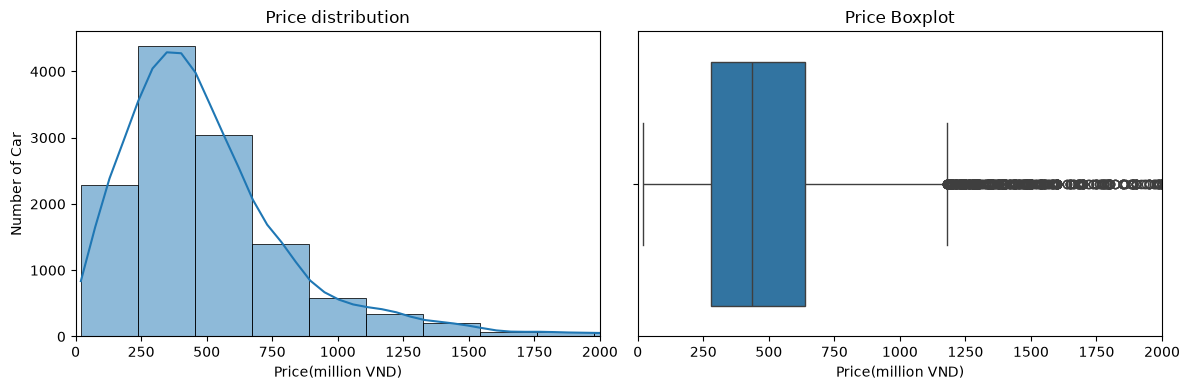

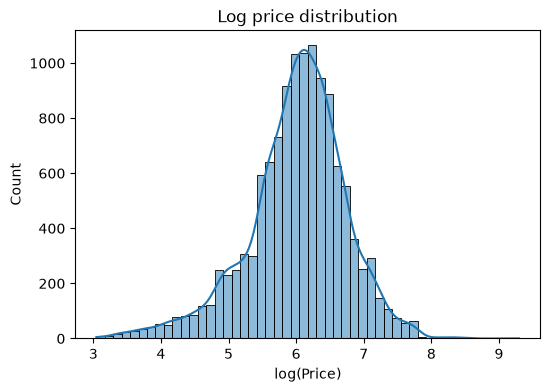

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["price_million"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Price distribution")
ax[0].set_xlabel("Price(million VND)")
ax[0].set_ylabel("Number of Car")
ax[0].set_xlim(0, 2000) #tránh outliner kéo
sns.boxplot(x=df["price_million"], ax=ax[1])
ax[1].set_title("Price Boxplot")
ax[1].set_xlabel("Price(million VND)")
ax[1].set_xlim(0, 2000) #tránh outliner kéo

plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 4))
sns.histplot(np.log1p(df["price_million"]), bins=50, kde=True)
plt.title("Log price distribution")
plt.xlabel("log(Price)")
plt.show()

**Nhận xét giá phân bố:**
- Giá lệch phải mạnh: phần lớn giá xe nằm trong khoảng 0-750 triệu vnđ , nhiều nhất khi giá từ 250-500 triệu vnđ.
- Có 113 số xe có giá hơn 2000 triệu vnđ, cao nhất là 10900 triệu vnđ với giá trung bình là 516 triệu vnđ.
- Giá trung vị khoảng 435 triệu vnđ, có rất nhiều outlier từ khoảng 1200 triệu vnđ trở lên.
- Biểu đồ log(price) có dạng chuông , cân đối xung quanh đỉnh ở log = 6.
- Kết luận: nên log-transform giá khi huấn luyện mô hình và xử lý outlier.

In [6]:
print(df["price_million"].describe())
print("Số xe giá > 2000 triệu:", (df["price_million"] > 2000).sum())
print("Giá cao nhất:", df["price_million"].max())

count    12494.000000
mean       516.342953
std        396.044710
min         20.000000
25%        279.000000
50%        435.000000
75%        639.000000
max      10900.000000
Name: price_million, dtype: float64
Số xe giá > 2000 triệu: 113
Giá cao nhất: 10900.0


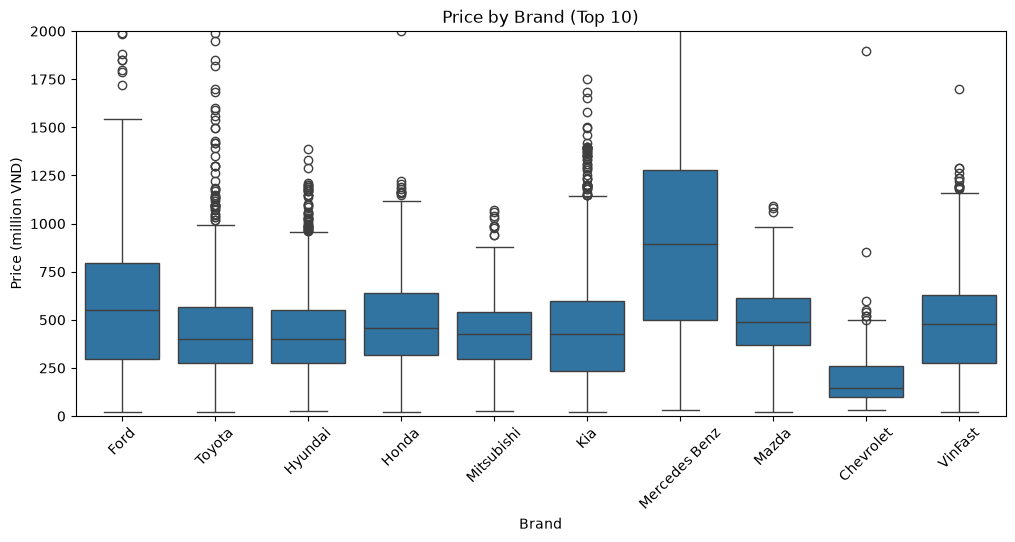

,count,median,mean
carbrand_name,,,
Mercedes Benz,686,895.0,938.148754
Ford,1559,549.0,584.812033
Mazda,740,489.0,491.299922
VinFast,781,480.0,479.361577
Honda,553,458.0,495.791826
Mitsubishi,883,428.0,417.491302
Kia,1323,425.0,473.250021
Toyota,2578,400.0,442.532498
Hyundai,1278,399.0,440.875172


In [17]:
top = df["carbrand_name"].value_counts().head(10).index

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df["carbrand_name"].isin(top)], x="carbrand_name", y="price_million")
plt.xticks(rotation=45)
plt.title("Price by Brand (Top 10)")
plt.xlabel("Brand")
plt.ylabel("Price (million VND)")
plt.ylim(0, 2000)   # tránh outlier kéo
plt.show()
df[df["carbrand_name"].isin(top)].groupby("carbrand_name")["price_million"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)


**Nhận xét giá theo hãng:**
- Biểu đồ chỉ gồm top 10 hãng nhiều xe nhất
- Mercedes Benz có giá trung vị cao nhất với khoảng 895 triệu vnđ, vượt hẳn các hãng còn lại với Chevrolet thấp nhất với khoảng 145 triệu vnđ.
- Ford, Toyota, Hyundai, Honda, Mitsubishi, Kia, Mazda, VinFast có trung vị gần nhau, khoảng 400-600 triệu vnđ.
- Mỗi hãng đều có outliner giá cao, đặc biệt là ở Toyota, Kia và Mercedes Benz.
- Kết luận: hãng xe ảnh hưởng rõ đến giá, cần đưa vào mô hình bằng One-Hot Encoding.

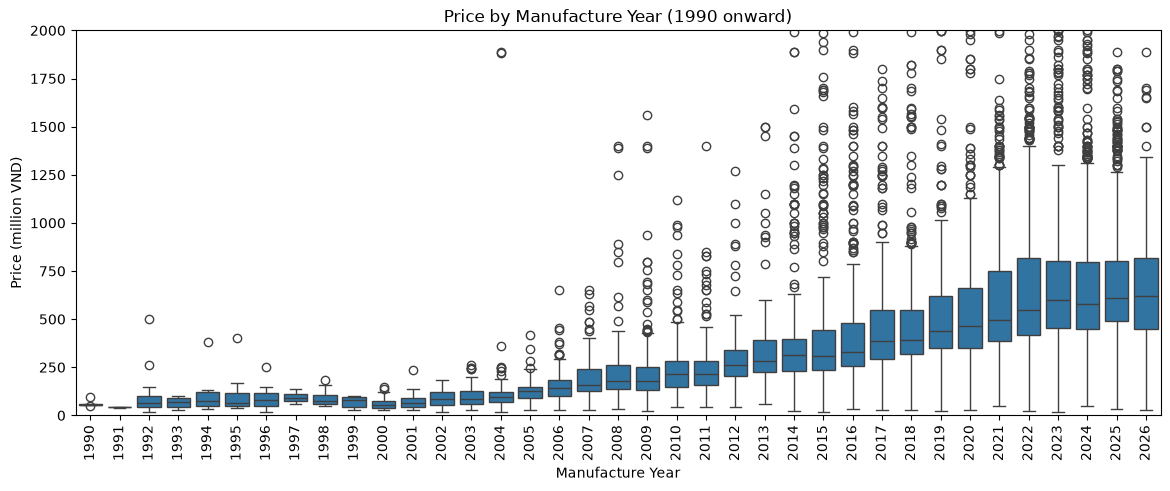

In [7]:
d = df[df["mfdate"] >= 1990]   # chỉ để vẽ, không ghi đè df gốc

plt.figure(figsize=(14, 5))
sns.boxplot(data=d, x="mfdate", y="price_million")
plt.xticks(rotation=90)
plt.title("Price by Manufacture Year (1990 onward)")
plt.xlabel("Manufacture Year")
plt.ylabel("Price (million VND)")
plt.ylim(0, 2000)
plt.show()

**Nhận xét giá theo năm sản xuất:**
- Càng mới thì giá càng cao. Giá trung vị tăng từ khoảng 215 triệu vnđ (2010) lên khoảng 600 triệu vnđ (2023).
- Giá trung vị đi lên gần như liên tục, chỉ có một đoạn giảm nhẹ ở năm 2020 so với 2019 , tăng rõ năm 2005 trở đi nhanh nhất khoảng 2012-2019 và 2021-2023
- Xe đời 2015 trở về sau có nhiều outlier giá cao, trùng với các hãng sang đời mới.
- Không nhiều outliner trước năm 2003
- Các năm trước 1990 có rất ít xe nên đã loại khỏi biểu đồ.
- Kết luận: năm sản xuất cũng là yếu tố có ảnh hưởng rõ rệt đến giá.

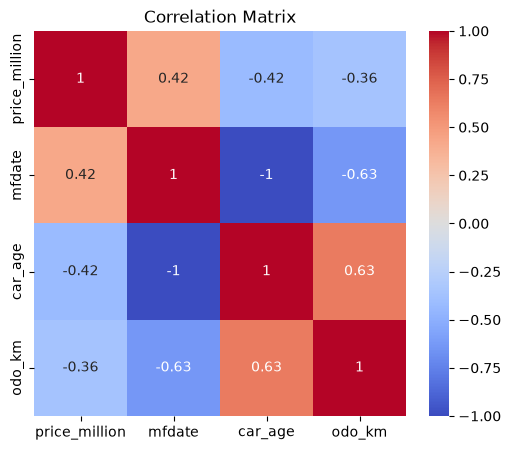

In [8]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["price_million", "mfdate", "car_age", "odo_km"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

**Nhận xét ma trận tương quan:**
- mfdate và car_age có r = -1: hai biến chứa cùng một thông tin (car_age tính từ mfdate và ngược lại), chỉ nên giữ một biến khi xây mô hình.
- Giá (price_million)tương quan dương với mfdate (0.42) và âm với car_age (-0.42) : xe càng mới giá càng cao
- Giá (price_million) tương quan âm với odo_km (-0.36) : xe chạy càng nhiều km thì giá càng thấp, nhưng ảnh hưởng yếu hơn năm sản xuất.
- car_age và odo_km tương quan dương (0.63): xe càng cũ chạy càng xa,
- Kết luận: mfdate là biến ảnh hưởng mạnh nhất đến giá trong ba biến số, odo_km ảnh hưởng ở mức trung bình.

## Kết luận EDA
1. Giá lệch phải mạnh, nhiều outlier: cần log-transform giá và xử lý outlier.
2. Hãng xe ảnh hưởng rõ đến giá.
3. Năm sản xuất là yếu tố ảnh hưởng mạnh và rõ nhất.
4. mfdate và car_age trùng thông tin, chỉ dùng một biến.
5. odo_km tương quan nghịch với giá (-0.36) và năm sản xuất (-0.63).
6. Đề xuất: dùng hãng (One-Hot), mfdate hoặc car_age, odo_km làm đặc trưng chính.